In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix

In [3]:
df = pd.read_csv('clean_resume_data.csv')

In [4]:
df.head()

,ID,Category,Feature
0,16852973,HR,hr administrator marketing associate hr admini...
1,22323967,HR,hr specialist hr operations summary media prof...
2,33176873,HR,hr director summary years experience recruitin...
3,27018550,HR,hr specialist summary dedicated driven dynamic...
4,17812897,HR,hr manager skill highlights hr skills hr depar...


In [5]:
df.shape

(2484, 3)

### Exploratory Data Analysis :

In [7]:
df['Category'].value_counts()

Category
INFORMATION-TECHNOLOGY    120
BUSINESS-DEVELOPMENT      120
ADVOCATE                  118
CHEF                      118
ENGINEERING               118
ACCOUNTANT                118
FINANCE                   118
FITNESS                   117
AVIATION                  117
SALES                     116
BANKING                   115
HEALTHCARE                115
CONSULTANT                115
CONSTRUCTION              112
PUBLIC-RELATIONS          111
HR                        110
DESIGNER                  107
ARTS                      103
TEACHER                   102
APPAREL                    97
DIGITAL-MEDIA              96
AGRICULTURE                63
AUTOMOBILE                 36
BPO                        22
Name: count, dtype: int64

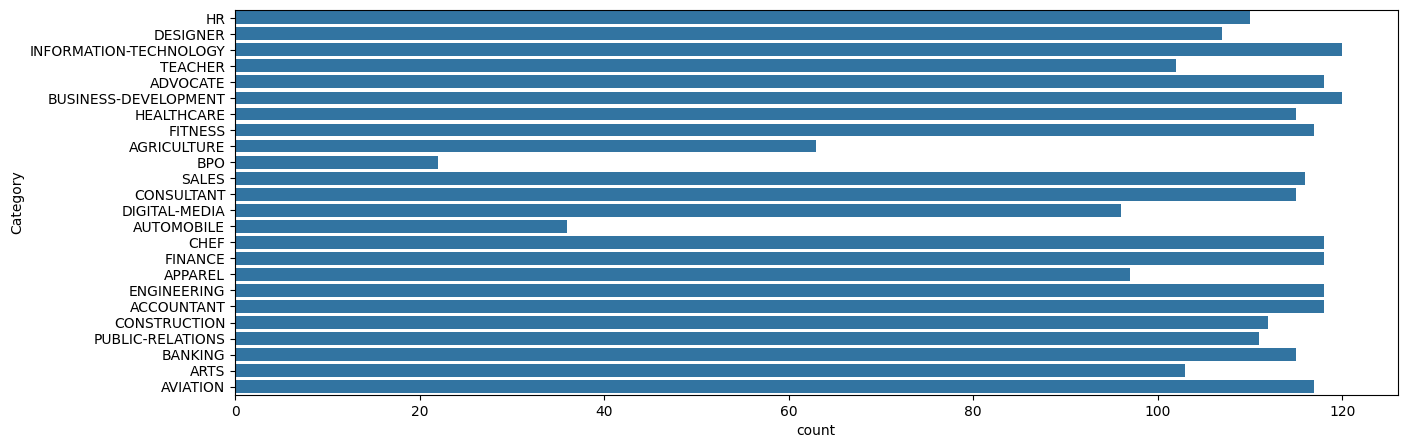

In [8]:
plt.figure(figsize = (15,5))
sns.countplot(df['Category'])
plt.show()

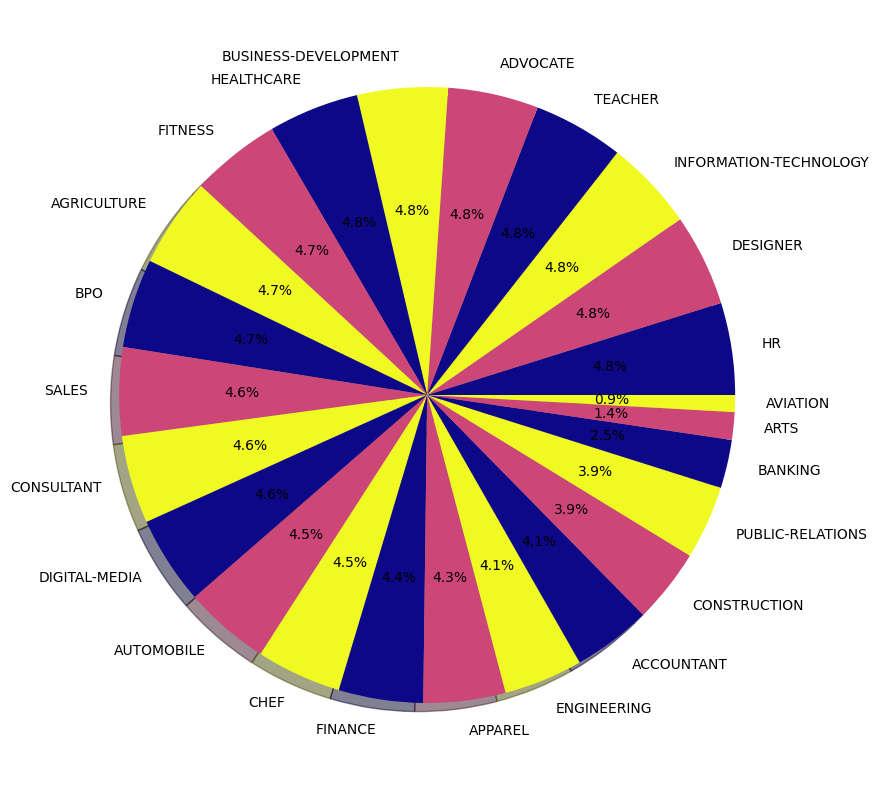

In [10]:
counts = df['Category'].value_counts()
labels = df['Category'].unique()
plt.figure(figsize=(15,10))

plt.pie(counts,labels=labels,autopct='%1.1f%%',shadow=True, colors=plt.cm.plasma(np.linspace(0,1,3)))
plt.show()

### Balance Dataset

In [13]:
from sklearn.utils import resample

# Define the maximum count among all categories
max_count = df['Category'].value_counts().max()

# Resample each category to match the maximum count
balanced_data = []
for category in df['Category'].unique():
    category_data = df[df['Category'] == category]
    if len(category_data) < max_count:
        # Perform oversampling for categories with fewer samples
        balanced_category_data = resample(category_data, replace=True, n_samples=max_count, random_state=42)
    else:
        # Perform undersampling for categories with more samples
        balanced_category_data = resample(category_data, replace=False, n_samples=max_count, random_state=42)
    balanced_data.append(balanced_category_data)

# Concatenate the balanced data for all categories
balanced_df = pd.concat(balanced_data)

In [14]:
# balanced_df.isnull().sum()
balanced_df.dropna(inplace=True)

### Train Test Split

In [15]:
X = balanced_df['Feature']
y = balanced_df['Category']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

### Encoding (TF-IDF)

In [16]:
tfidf_vectorizer = TfidfVectorizer()
X_train_tfidf = tfidf_vectorizer.fit_transform(X_train)
X_test_tfidf = tfidf_vectorizer.transform(X_test)

### Train Multiple models

In [21]:
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import MultinomialNB
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.neighbors import KNeighborsClassifier
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, classification_report

In [22]:
models = {
    "Random Forest": RandomForestClassifier(n_estimators=200),
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Linear SVM": LinearSVC(),
    "Naive Bayes": MultinomialNB(),
    "Gradient Boosting": GradientBoostingClassifier(),
    "KNN": KNeighborsClassifier(n_neighbors=5)
}

results = {}

for name, model in models.items():
    model.fit(X_train_tfidf, y_train)
    y_pred = model.predict(X_test_tfidf)
    
    acc = accuracy_score(y_test, y_pred)
    results[name] = acc
    
    print("Model:", name)
    print("Accuracy:", acc)
    print(classification_report(y_test, y_pred))
    print("-"*50)

Model: Random Forest
Accuracy: 0.8472222222222222
                        precision    recall  f1-score   support

            ACCOUNTANT       0.77      0.95      0.85        21
              ADVOCATE       1.00      0.76      0.86        29
           AGRICULTURE       0.94      0.74      0.83        23
               APPAREL       0.89      0.81      0.85        21
                  ARTS       1.00      0.59      0.74        22
            AUTOMOBILE       1.00      1.00      1.00        19
              AVIATION       0.91      1.00      0.95        30
               BANKING       1.00      0.83      0.90        23
                   BPO       1.00      1.00      1.00        15
  BUSINESS-DEVELOPMENT       0.50      0.72      0.59        18
                  CHEF       0.97      1.00      0.98        28
          CONSTRUCTION       0.86      1.00      0.93        25
            CONSULTANT       1.00      0.68      0.81        31
              DESIGNER       0.96      0.86      0.91

In [23]:
result_df = pd.DataFrame(list(results.items()), columns=["Model","Accuracy"])
result_df = result_df.sort_values(by="Accuracy", ascending=False)
print(result_df)

                 Model  Accuracy
4    Gradient Boosting  0.885417
2           Linear SVM  0.873264
0        Random Forest  0.847222
1  Logistic Regression  0.763889
3          Naive Bayes  0.666667
5                  KNN  0.607639


In [24]:
best_model = LinearSVC()
best_model.fit(X_train_tfidf, y_train)

y_pred = best_model.predict(X_test_tfidf)

print("Final Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))

Final Accuracy: 0.8732638888888888
                        precision    recall  f1-score   support

            ACCOUNTANT       0.95      0.95      0.95        21
              ADVOCATE       0.96      0.83      0.89        29
           AGRICULTURE       0.86      0.83      0.84        23
               APPAREL       0.95      0.86      0.90        21
                  ARTS       0.89      0.77      0.83        22
            AUTOMOBILE       0.95      1.00      0.97        19
              AVIATION       0.88      0.97      0.92        30
               BANKING       0.95      0.78      0.86        23
                   BPO       0.94      1.00      0.97        15
  BUSINESS-DEVELOPMENT       0.57      0.67      0.62        18
                  CHEF       0.96      0.96      0.96        28
          CONSTRUCTION       0.89      1.00      0.94        25
            CONSULTANT       1.00      0.71      0.83        31
              DESIGNER       0.96      0.93      0.95        28
    

In [26]:
pickle.dump(best_model, open('best_resume_model.pkl','wb'))
pickle.dump(tfidf_vectorizer, open('tfidf_vectorizer.pkl','wb'))

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [27]:
cm = confusion_matrix(y_test, y_pred)
print(cm)

[[20  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  1  0  0  0  0  0  0  0]
 [ 0 24  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  1  1  0  0  3  0]
 [ 0  0 19  0  0  0  1  0  0  0  0  0  0  0  0  0  0  0  1  0  1  1  0  0]
 [ 0  0  0 18  0  0  0  0  0  0  0  0  0  0  0  0  0  1  0  0  0  0  2  0]
 [ 0  0  0  0 17  0  1  0  1  0  1  0  0  0  1  0  0  0  0  0  1  0  0  0]
 [ 0  0  0  0  0 19  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  0  1  0  0 29  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0  0 18  0  0  0  0  0  0  0  0  3  1  1  0  0  0  0  0]
 [ 0  0  0  0  0  0  0  0 15  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0  0  0  0 12  0  0  0  0  1  0  0  0  1  0  2  0  2  0]
 [ 0  0  0  0  0  0  0  0  0  1 27  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0  0  0  0  0  0 25  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  1  1  0  0  0  0  0  0  1  0  2 22  0  0  1  0  0  1  1  0  1  0  0]
 [ 0  0  0  0  0  0  1  0

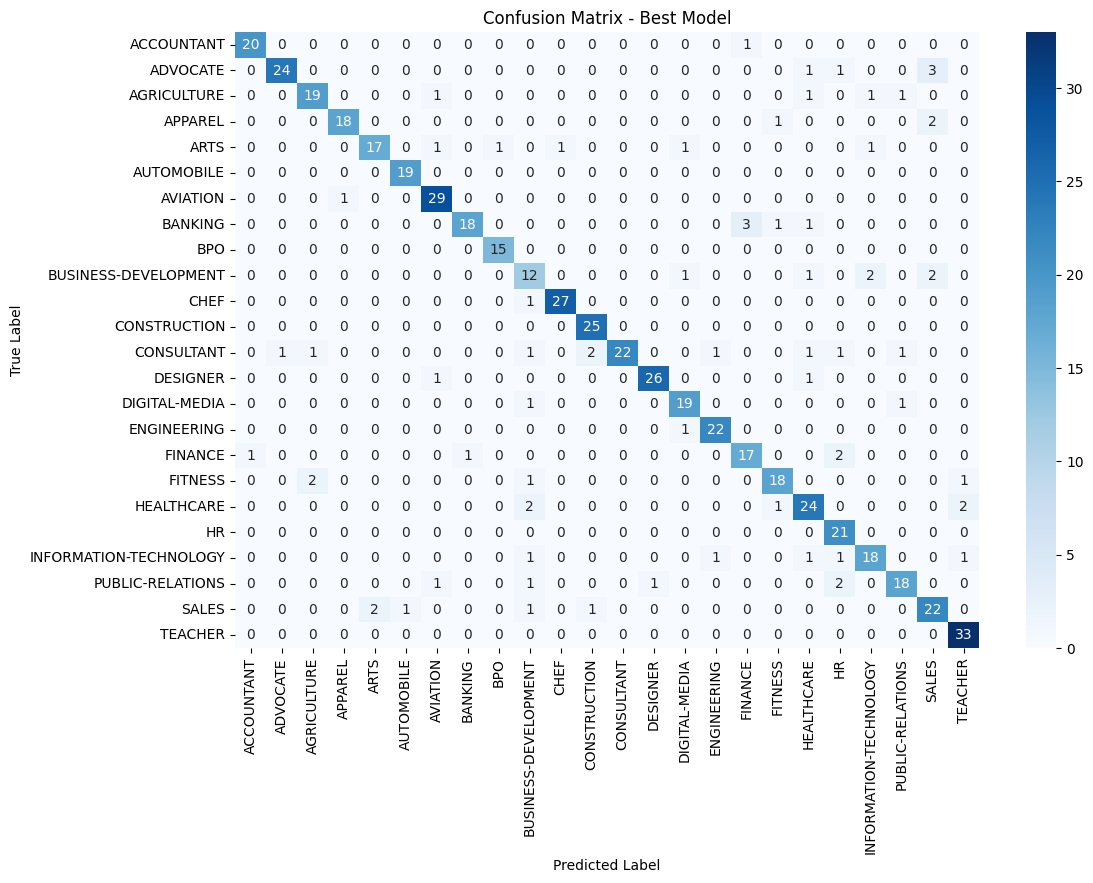

In [29]:
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
y = le.fit_transform(df['Category'])

plt.figure(figsize=(12,8))

sns.heatmap(cm,
            annot=True,
            fmt='d',
            cmap='Blues',
            xticklabels=le.classes_,
            yticklabels=le.classes_)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix - Best Model")
plt.show()